# 04 — Final test on the untouched 2025 season

**Question:** does the model trained on 2024 work in a **new season** it has never seen?

Cross-validation (notebook 03) estimated how the model does on *new places* within 2024. A new year is a harder
test: different weather and flooding dates, a second satellite (Sentinel-1C joined Sentinel-1A in spring 2025),
and about 20 % more rice parcels declared (1,566 → 1,871 in the RPG). This is called **domain shift**.

**Ground rules, written before any 2025 score is computed:**
- The model, its 0.5 threshold, the features, the satellite track and the season windows are **frozen**
  (`outputs/model.joblib`, `outputs/model.json`). Nothing is changed after seeing the 2025 results, whatever they are.
- The only change allowed would be fixing a **bug** in the data pipeline, documented as such. Tuning is not allowed.
- **Expectation:** cross-validated F1 on 2024 was **0.967 ± 0.013**. A modest drop in a new year would be normal.
- The frozen LightGBM is **the** result. The physics rule and logistic regression (also trained on all of 2024) are
  shown **for reference only**; they are not used to choose anything.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import ConfusionMatrixDisplay

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))
plt.rcParams["figure.dpi"] = 72  # keeps the saved notebook small

from ricesar.config import DATA_DIR, load_config
from ricesar.download import patch_name, patches_with_parcels
from ricesar.features import build_dataset, grid_dates
from ricesar.labels import load_labels, project
from ricesar.models import block_bootstrap_ci, grid_features, make_models, scores

config = load_config(PROJECT_ROOT / "configs" / "camargue.toml")
TRAIN_YEAR, TEST_YEAR = 2024, 2025

model = joblib.load(PROJECT_ROOT / "outputs" / "model.joblib")
meta = json.loads((PROJECT_ROOT / "outputs" / "model.json").read_text())
print("frozen model:", meta["model"], "| trained on", meta["trained_on"], "| track", meta["track"],
      "|", len(meta["features"]), "input columns")
assert meta["track"] == config["s1"]["track"] and meta["windows"] == config["features"]

frozen model: lightgbm | trained on 2024 | track 05:50 | 75 input columns


## 1. Build the 2025 table with the same pipeline

`scripts/download_s1.py --year 2025 --area full` downloaded the same 10 km squares with the same track.
`build_dataset` is the same function as for 2024 (notebook 02): same 12-day grid from 1 March, same windows, same
rule for leaving out parcels with too few clean pixels. In 2025 two satellites fly this track, so each 12-day bin
holds about two passes, which are averaged.

In [2]:
labels_test = load_labels(config, TEST_YEAR)
bboxes = patches_with_parcels(config, labels_test)
squares_train = {patch_name(b) for b in patches_with_parcels(config, load_labels(config, TRAIN_YEAR))}
squares_test = {patch_name(b) for b in bboxes}
print(f"{len(squares_test)} squares; same as {TRAIN_YEAR}: {squares_test == squares_train}")

eopatch_dirs = [DATA_DIR / "raw" / f"eopatches_{config['name']}_full_{TEST_YEAR}" / patch_name(b) for b in bboxes]
print("missing EOPatches:", [p.name for p in eopatch_dirs if not p.exists()] or "none")

dataset_path = DATA_DIR / "processed" / f"dataset_{config['name']}_{TEST_YEAR}.csv"
if dataset_path.exists():
    test = pd.read_csv(dataset_path, index_col="pid")
else:
    test, excluded = build_dataset(config, TEST_YEAR, eopatch_dirs, labels_test, bboxes)
    test.to_csv(dataset_path)
train = pd.read_csv(DATA_DIR / "processed" / f"dataset_{config['name']}_{TRAIN_YEAR}.csv", index_col="pid")

33 squares; same as 2024: True
missing EOPatches: none


**Sanity checks before scoring** (no performance numbers yet): same columns, no missing values, similar size.

In [3]:
missing_columns = [c for c in meta["features"] if c not in test.columns]
assert not missing_columns, missing_columns
assert not test[meta["features"]].isna().any().any(), "missing values in model inputs"

pd.DataFrame({
    "parcels in table": [len(train), len(test)],
    "rice parcels": [int(train["is_rice"].sum()), int(test["is_rice"].sum())],
    "rice share": [f"{train['is_rice'].mean():.1%}", f"{test['is_rice'].mean():.1%}"],
    "spatial blocks": [train["block"].nunique(), test["block"].nunique()],
}, index=[f"{TRAIN_YEAR} (training)", f"{TEST_YEAR} (test)"])

,parcels in table,rice parcels,rice share,spatial blocks
2024 (training),13613,1524,11.2%,98
2025 (test),13807,1823,13.2%,98


## 2. Does 2025 look like 2024? (input shift, still no scores)

If the radar signal itself changed (another satellite, a wetter spring, a later flooding), the model sees inputs
unlike its training data. We compare the inputs first, without labels-vs-predictions.

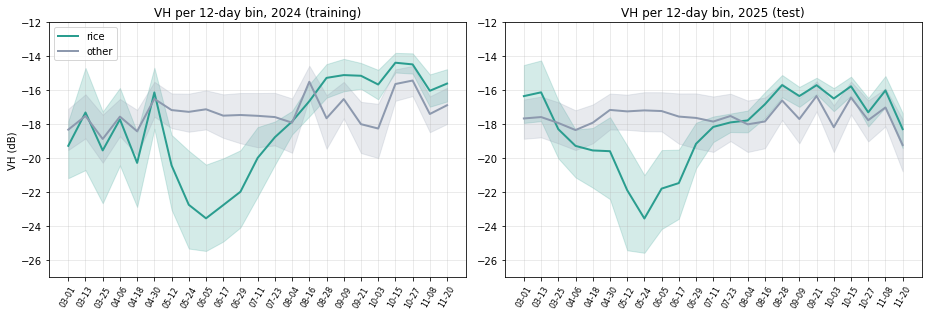

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, frame, year) in zip(axes, [("2024 (training)", train, TRAIN_YEAR), ("2025 (test)", test, TEST_YEAR)]):
    dates = grid_dates(config, year)
    vh_cols = [f"VH_db_{b:02d}" for b in range(len(dates))]
    for is_rice, color, label in [(True, "#2a9d8f", "rice"), (False, "#8d99ae", "other")]:
        values = frame.loc[frame["is_rice"] == is_rice, vh_cols]
        ax.plot(dates.strftime("%m-%d"), values.median(), color=color, linewidth=2, label=label)
        ax.fill_between(dates.strftime("%m-%d"), values.quantile(0.25), values.quantile(0.75), color=color, alpha=0.2)
    ax.set_title(f"VH per 12-day bin, {name}")
    ax.set_ylim(-27, -12)
    ax.tick_params(axis="x", labelrotation=60, labelsize=8)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("VH (dB)")
axes[0].legend()
plt.tight_layout()
plt.show()

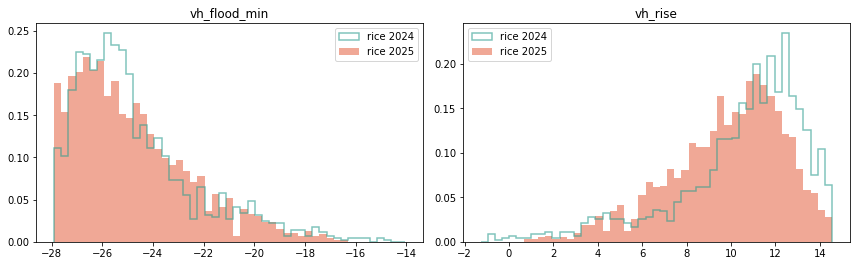

2024   2025  2025 − 2024
is_rice                                        
False   vh_flood_min -18.76 -18.52         0.24
        vh_peak_max  -15.24 -15.90        -0.66
        vh_rise        3.20   2.30        -0.89
True    vh_flood_min -25.41 -25.61        -0.20
        vh_peak_max  -14.13 -15.30        -1.17
        vh_rise       11.29  10.25        -1.04

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, feature in zip(axes, ["vh_flood_min", "vh_rise"]):
    bins = np.linspace(train[feature].quantile(0.005), train[feature].quantile(0.995), 50)
    for frame, year, style in [(train, TRAIN_YEAR, "step"), (test, TEST_YEAR, "stepfilled")]:
        ax.hist(frame.loc[frame["is_rice"], feature], bins=bins, density=True, histtype=style, alpha=0.6,
                linewidth=1.5, color="#2a9d8f" if year == TRAIN_YEAR else "#e76f51", label=f"rice {year}")
    ax.set_title(feature)
    ax.legend()
plt.tight_layout()
plt.show()

shift = pd.DataFrame({
    year: frame.groupby("is_rice")[["vh_flood_min", "vh_peak_max", "vh_rise"]].median().stack()
    for year, frame in [(TRAIN_YEAR, train), (TEST_YEAR, test)]
})
shift["2025 − 2024"] = shift[TEST_YEAR] - shift[TRAIN_YEAR]
shift.round(2)

## 3. The test (run once)

The frozen model predicts every 2025 parcel. The **95 % confidence interval** comes from a *block bootstrap*:
we resample the 5 km blocks 1,000 times with replacement and recompute the scores. That shows how much the score
could vary with a different sample of areas. Resampling single parcels would ignore that neighbours are alike and
give intervals that are too narrow.

In [6]:
y_test = test["is_rice"].astype(bool).to_numpy()
proba = model.predict_proba(test[meta["features"]])[:, 1]
pred = proba >= 0.5

result = pd.Series(scores(y_test, pred, proba)).to_frame("2025 test")
result = result.join(block_bootstrap_ci(y_test, pred, proba, test["block"].to_numpy(), n=1000, seed=0))
print(f"Frozen {meta['model']}, trained on {TRAIN_YEAR}, tested on {TEST_YEAR} ({len(test)} parcels, {y_test.sum()} rice)")
result.round(3)

Frozen lightgbm, trained on 2024, tested on 2025 (13807 parcels, 1823 rice)


,2025 test,ci_low,ci_high
accuracy,0.982,0.976,0.988
precision,0.944,0.919,0.964
recall,0.918,0.897,0.936
f1,0.931,0.913,0.946
pr_auc,0.971,0.960,0.979


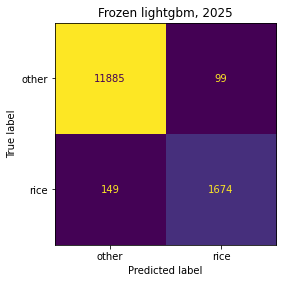

In [7]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["other", "rice"], ax=ax, colorbar=False)
ax.set_title(f"Frozen {meta['model']}, {TEST_YEAR}")
plt.show()

## 4. References: the simpler models in the new year

Trained on all of 2024 with exactly the settings of notebook 03, scored on 2025. For context only.

In [8]:
y_train = train["is_rice"].astype(bool)
rows = {}
for name, (estimator, columns) in make_models(grid_features(train)).items():
    if name in ("majority", "lightgbm"):
        continue
    reference = clone(estimator).fit(train[columns], y_train)
    ref_proba = reference.predict_proba(test[columns])[:, 1]
    rows[f"{name} (reference)"] = scores(y_test, reference.predict(test[columns]).astype(bool), ref_proba)
rows[f"{meta['model']} (frozen, the result)"] = result["2025 test"].to_dict()
test_table = pd.DataFrame(rows).T
test_table.round(3)

,accuracy,precision,recall,f1,pr_auc
physics rule (reference),0.948,0.862,0.719,0.784,0.878
logistic regression (reference),0.950,0.925,0.673,0.779,0.888
"lightgbm (frozen, the result)",0.982,0.944,0.918,0.931,0.971


## 5. Cross-validation (2024) vs test (2025)

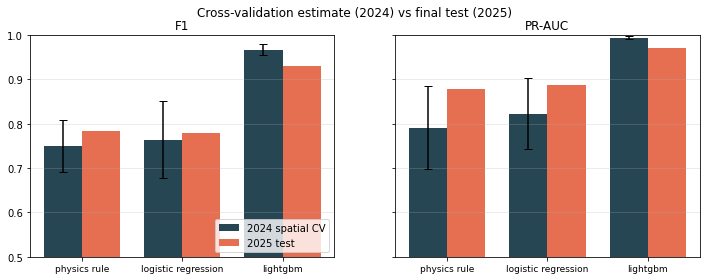

In [9]:
cv = pd.read_csv(PROJECT_ROOT / "reports" / "cv_results.csv", header=[0, 1], index_col=[0, 1]).loc["spatial"]
names = {"physics rule": "physics rule (reference)", "logistic regression": "logistic regression (reference)",
         meta["model"]: f"{meta['model']} (frozen, the result)"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, metric in zip(axes, ["f1", "pr_auc"]):
    x = np.arange(len(names))
    ax.bar(x - 0.19, [cv.loc[m, (metric, "mean")] for m in names], 0.38,
           yerr=[cv.loc[m, (metric, "std")] for m in names], capsize=4, color="#264653", label="2024 spatial CV")
    ax.bar(x + 0.19, [test_table.loc[n, metric] for n in names.values()], 0.38, color="#e76f51", label="2025 test")
    ax.set_xticks(x)
    ax.set_xticklabels(list(names), fontsize=9)
    ax.set_title(metric.upper().replace("_", "-"))
    ax.set_ylim(0.5, 1.0)
    ax.grid(axis="y", alpha=0.3)
axes[0].legend(loc="lower right")
fig.suptitle("Cross-validation estimate (2024) vs final test (2025)")
fig.savefig(PROJECT_ROOT / "reports" / "figures" / "04_cv_vs_test.png", dpi=90, bbox_inches="tight")
plt.show()

## 6. Where does the frozen model go wrong in 2025?

In [10]:
analysis = test[["is_rice", "code_cultu", "group_name", "surf_parc"]].assign(proba=proba, pred=pred)
false_alarms = analysis[analysis["pred"] & ~analysis["is_rice"]]
misses = analysis[~analysis["pred"] & analysis["is_rice"]]
print(f"{len(false_alarms)} false alarms, {len(misses)} missed rice parcels")
print("False alarms by declared crop code:", false_alarms["code_cultu"].value_counts().head(8).to_dict())

size_bins = pd.cut(analysis.loc[analysis["is_rice"], "surf_parc"], [0, 2, 5, 10, 1000],
                   labels=["< 2 ha", "2–5 ha", "5–10 ha", "> 10 ha"])
recall_by_size = analysis.loc[analysis["is_rice"], "pred"].groupby(size_bins, observed=False).agg(["mean", "size"])
recall_by_size.columns = ["recall", "rice parcels"]
recall_by_size.round(3)

99 false alarms, 149 missed rice parcels
False alarms by declared crop code: {'BDH': 28, 'PTR': 10, 'SOG': 9, 'TRN': 8, 'CZH': 8, 'PTC': 7, 'LUZ': 7, 'BTH': 6}


,recall,rice parcels
surf_parc,,
< 2 ha,0.916,249
2–5 ha,0.924,695
5–10 ha,0.925,424
> 10 ha,0.905,455


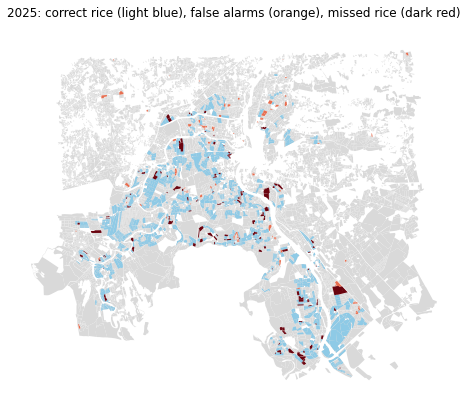

In [11]:
labels_utm = project(labels_test, bboxes[0].crs.pyproj_crs()).set_index("pid")
outcome = pd.Series("correct", index=analysis.index)
outcome[analysis["pred"] & ~analysis["is_rice"]] = "false alarm"
outcome[~analysis["pred"] & analysis["is_rice"]] = "missed rice"
mapped = labels_utm.loc[analysis.index].assign(outcome=outcome.values)

fig, ax = plt.subplots(figsize=(8, 8))
mapped[mapped["outcome"] == "correct"].plot(ax=ax, color="#d9d9d9", linewidth=0)
mapped[(mapped["outcome"] == "correct") & analysis["is_rice"].values].plot(ax=ax, color="#8ecae6", linewidth=0)
mapped[mapped["outcome"] == "false alarm"].plot(ax=ax, color="#e76f51", linewidth=0)
mapped[mapped["outcome"] == "missed rice"].plot(ax=ax, color="#6a040f", linewidth=0)
ax.set_title(f"{TEST_YEAR}: correct rice (light blue), false alarms (orange), missed rice (dark red)")
ax.set_axis_off()
fig.savefig(PROJECT_ROOT / "reports" / "figures" / "04_error_map.png", dpi=90, bbox_inches="tight")
plt.show()

In [12]:
analysis["disagreement"] = np.where(analysis["is_rice"], 1 - analysis["proba"], analysis["proba"])
analysis.sort_values("disagreement", ascending=False).head(15)[
    ["code_cultu", "group_name", "surf_parc", "is_rice", "proba"]
].round(3)

,code_cultu,group_name,surf_parc,is_rice,proba
pid,,,,,
17598,RIZ,rice,2.39,True,0.0
2590,RIZ,rice,1.37,True,0.0
2203,RIZ,rice,1.74,True,0.0
17601,RIZ,rice,3.83,True,0.0
3890,RIZ,rice,6.42,True,0.0
6650,RIZ,rice,7.06,True,0.0
4170,RIZ,rice,176.46,True,0.0
17602,RIZ,rice,1.50,True,0.0
17600,RIZ,rice,1.70,True,0.0


In [13]:
out = test_table.copy()
out.loc[f"{meta['model']} (frozen, the result)", ["f1_ci_low", "f1_ci_high"]] = result.loc["f1", ["ci_low", "ci_high"]].values
out.to_csv(PROJECT_ROOT / "reports" / "test_results.csv")
print("saved reports/test_results.csv")

saved reports/test_results.csv


## Summary

**The frozen model works in the new season, with a real but modest drop.**

| | 2024 spatial CV | **2025 test** (95 % CI, block bootstrap) |
|---|---|---|
| F1 | 0.967 ± 0.013 | **0.931** (0.913–0.946) |
| precision | 0.975 | 0.944 |
| recall | 0.960 | 0.918 |
| PR-AUC | 0.994 | 0.971 |

- **The drop is real:** the 2025 interval doesn't include the CV estimate. Cross-validation within one year measured
  how the model does in *new places*, not in a *new year*, so it was optimistic for this question. That is exactly why
  a separate, untouched test season was kept.
- **What changed (section 2):** the 2025 season came **earlier** (rice went dark 2–3 weeks earlier, from late March)
  and **peaked lower** (rice median about −15.7 dB vs −14.3 dB in 2024; the rise is about 1 dB smaller). The dip-and-rise shape
  is the same, but its timing moved.
- **Why it hurts LightGBM more than the simple models:** LightGBM partly learned *on which dates* 2024 rice was dark or bright
  (it uses each 12-day bin as a separate input). The rule and logistic regression use "lowest VH anywhere between mid-April
  and mid-June", which tolerates a shifted calendar, and they even scored a bit higher than in CV (F1 0.78 vs 0.75–0.76).
  Still, the frozen LightGBM remains far ahead (0.93 vs 0.78).
- **Errors:** false alarms are mostly durum wheat (BDH) and other irrigated crops. Misses are spread over all parcel sizes
  (recall about 0.91–0.93), with a few clusters, e.g. in the south-east of the delta, that look like whole farms flooding at an unusual time.
- **Lessons for a next version** (not applied here, the test is done): train on **several seasons** so the model sees
  different calendars, and/or add **timing-tolerant features** (e.g. align each parcel's series on its own flooding date).
  Any such change would need a *new* untouched test season (e.g. 2026).